In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
EXTRACTED_REP_PATH = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/target_hidden_states.pt" #Change this!
data = torch.load(
    EXTRACTED_REP_PATH,
    map_location="cpu",
)

print(data.keys())

dict_keys(['image_paths', 'conditions', 'num_distractors', 'trials', 'image_width', 'image_height', 'target_x', 'target_y', 'target_x_px', 'target_y_px', 'bbox_left', 'bbox_top', 'bbox_right', 'bbox_bottom', 'raw_h', 'raw_w', 'token_h', 'token_w', 'merge_size', 'raw_patch_x', 'raw_patch_y', 'target_token_x', 'target_token_y', 'target_token_idx', 'bbox_token_indices', 'window3x3_indices', 'center_token_hidden', 'bbox_mean_hidden', 'window3x3_mean_hidden', 'bbox_hidden', 'window3x3_hidden'])


# Hidden State Dictionary Keys 
## - I had chatGPT generate this lol but it went through it and it explained it correctly

The extracted `.pt` file stores several different representations of the target region in the image. Since a visual object can span multiple image tokens, we store both a **single closest token** and several **multi-token aggregations**.

---

## `bbox_token_indices`

**Type:** `list[list[int]]`

The image token indices that fall inside the target's bounding box.

For example:

```python
data["bbox_token_indices"][0]
# [180, 181, 196, 197]
```

This means that the target object overlaps four image tokens:

```
180 181
196 197
```

These indices refer to positions within the flattened image token grid (16×16 = 256 tokens for a 448×448 image).

---

## `window3x3_indices`

**Type:** `list[list[int]]`

The indices of the 3×3 neighborhood surrounding the center token.

For example:

```python
data["window3x3_indices"][0]
# [163, 164, 165,
#  179, 180, 181,
#  195, 196, 197]
```

This representation attempts to capture not only the target itself, but also nearby contextual information.

Visually:

```
163 164 165
179 180 181
195 196 197
```

where `180` is the center token.

---

# Hidden State Representations

All hidden state tensors have shape

```python
(num_examples, num_layers, hidden_dim)
```

For Qwen2.5-VL-7B:

```python
hidden_dim = 3584
num_layers = 28
```

---

## `center_token_hidden`

**Shape:**

```python
[num_examples, num_layers, hidden_dim]
```

The hidden states of the **single closest image token** to the target center.

This is the simplest representation and is analogous to using one "representative patch" for the object.

Example:

```python
h = data["center_token_hidden"][example, layer]
# shape: [3584]
```

---

## `bbox_mean_hidden`

**Shape:**

```python
[num_examples, num_layers, hidden_dim]
```

The mean hidden state over all image tokens inside the target's bounding box.

Mathematically:

```python
bbox_mean_hidden
=
(1/N)
Σ h_i
```

where

- `h_i` are the token representations inside the object
- `N` is the number of tokens overlapping the object.

This is often a more stable object representation than a single token.

---

## `window3x3_mean_hidden`

**Shape:**

```python
[num_examples, num_layers, hidden_dim]
```

The mean hidden state over the 3×3 neighborhood surrounding the center token.

Mathematically:

```python
window3x3_mean_hidden
=
(1/9)
Σ h_i
```

This representation includes:

- the target token
- neighboring tokens
- local visual context

It can be useful when the object spans multiple patches or when nearby distractors influence the representation.

---

# Full Token-Level Representations

The previous tensors store **averages**. The following keys store the **individual token hidden states**.

---

## `bbox_hidden`

**Type:** `list[Tensor]`

Each element has shape:

```python
[num_layers, num_bbox_tokens, hidden_dim]
```

Example:

```python
data["bbox_hidden"][0].shape
# [29, 4, 3584]
```

This stores the hidden state of every token inside the target bounding box.

You can compute your own aggregations:

```python
bbox_mean = (
    data["bbox_hidden"][i]
    .mean(dim=1)
)
```

or study token-to-token variability inside the object.

---

## `window3x3_hidden`

**Type:** `list[Tensor]`

Each element has shape:

```python
[num_layers, 9, hidden_dim]
```

This stores the hidden states of all tokens in the 3×3 neighborhood.

Example:

```python
data["window3x3_hidden"][0].shape
# [29, 9, 3584]
```

This allows analyses such as:

- PCA of neighboring patches
- attention between target and context patches
- measuring representation spread around the object
- constructing custom object representations.

---

# TLDR

| Key | Recommended Use |
|------|----------------|
| `center_token_hidden` | closest patch to shape centroid |
| `bbox_mean_hidden` | Best approximation of the full object representation (uneven num of tokens) |
| `window3x3_mean_hidden` | Include local context around the object (might catch other shapes in high num_distractors) |
| `bbox_hidden` | Token-level analyses inside the object (uneven num of tokens) |
| `window3x3_hidden` | Study interactions between target and neighboring patches (might catch other shapes) |


Distractor counts: [ 0 10 15 20 25 30 35 40 45 50  5]


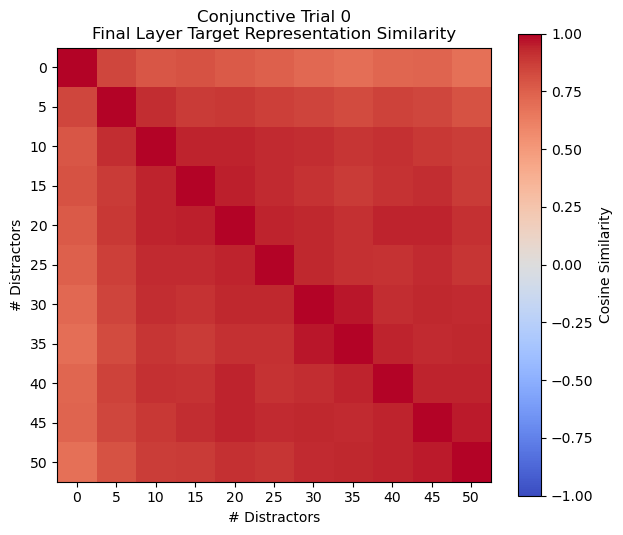

In [5]:

TRIAL = 0
CONDITION = "conjunctive"



conditions = np.array(data["conditions"])
trials = data["trials"].numpy()
num_distractors = data["num_distractors"].numpy()

#specify trial (if you want an individual trial) and conditions
mask = (
    (conditions == CONDITION)
    & (trials == TRIAL)
)

idx = np.where(mask)[0]

print(
    "Distractor counts:",
    num_distractors[idx]
)

#choose a representation from the ones listed above
reps = data[
    "bbox_mean_hidden"
][idx]

# choose layer (15th to last)
reps = reps[:, -15]



sim = cosine_similarity(
    reps.numpy()
)

# sort by distractor count
order = np.argsort(
    num_distractors[idx]
)

sim = sim[
    np.ix_(order, order)
]

distractors = (
    num_distractors[idx][order]
)


plt.figure(figsize=(7, 6))

im = plt.imshow(
    sim,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
)

plt.colorbar(
    im,
    label="Cosine Similarity"
)

plt.xticks(
    np.arange(len(distractors)),
    distractors,
)

plt.yticks(
    np.arange(len(distractors)),
    distractors,
)

plt.xlabel("# Distractors")
plt.ylabel("# Distractors")

plt.title(
    f"{CONDITION.capitalize()} Trial {TRIAL}\n"
    "Final Layer Target Representation Similarity"
)

plt.show()